# Optional Lab - Simple Neural Network
이번 실습에서는 Tensorflow를 사용하여 소규모 신경망을 구축해 보겠습니다.
<center> <img  src="./images/C2_W1_CoffeeRoasting.png" width="400" />   <center/>


In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('./deeplearning.mplstyle')
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from lab_utils_common import dlc
from lab_coffee_utils import load_coffee_data, plt_roast, plt_prob, plt_layer, plt_network, plt_output_unit
import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)
tf.autograph.set_verbosity(0)

## DataSet

In [2]:
X,Y = load_coffee_data();
print(X.shape, Y.shape)

(200, 2) (200, 1)


아래에 커피 로스팅 데이터를 그려보겠습니다. 두 가지 특징은 섭씨 온도와 분 단위의 지속 시간입니다. [집에서 커피 로스팅](https://www.merchantsofgreencoffee.com/how-to-roast-green-coffee-in-your-oven/)에서는 온도가 12~15분 사이로 유지되는 것이 가장 좋다고 제안합니다. 섭씨 175도에서 260도 사이여야 합니다. 물론 온도가 올라가면 지속시간은 줄어들겠죠.

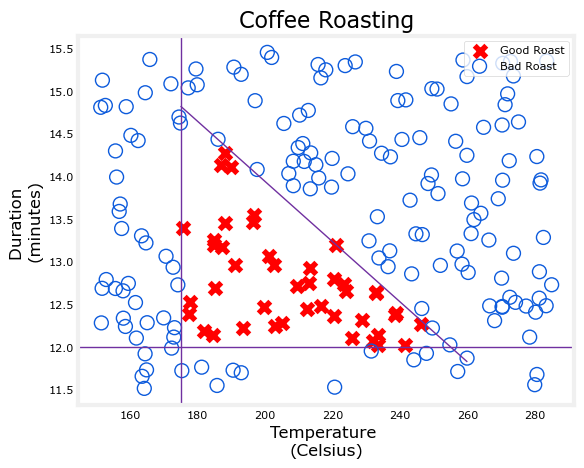

In [3]:
plt_roast(X,Y)

### Normalize Data
데이터에 가중치를 맞추는 것(역전파, 다음 주 강의에서 다룸)은 데이터가 정규화되면 더 빠르게 진행됩니다. 이는 데이터의 특징이 각각 유사한 범위를 갖도록 정규화되는 Course 1에서 사용한 것과 동일한 절차입니다.
아래 절차에서는 Keras [Normalization layer](https://keras.io/api/layers/preprocessing_layers/numerical/normalization/)를 사용합니다. 다음 단계가 있습니다.
- "정규화 레이어(Normalization Layer)"를 만듭니다. 여기에 적용된 것처럼 이는 모델의 레이어가 아닙니다.
- 데이터를 '적응(adapt)'합니다. 이는 데이터 세트의 평균과 분산을 학습하고 값을 내부적으로 저장합니다.
- 데이터를 정규화합니다.
학습된 모델을 활용하는 향후 데이터에 정규화를 적용하는 것이 중요합니다.

In [4]:
print(f"Temperature Max, Min pre normalization: {np.max(X[:,0]):0.2f}, {np.min(X[:,0]):0.2f}")
print(f"Duration    Max, Min pre normalization: {np.max(X[:,1]):0.2f}, {np.min(X[:,1]):0.2f}")
norm_l = tf.keras.layers.Normalization(axis=-1)
norm_l.adapt(X)  # learns mean, variance
Xn = norm_l(X)
print(f"Temperature Max, Min post normalization: {np.max(Xn[:,0]):0.2f}, {np.min(Xn[:,0]):0.2f}")
print(f"Duration    Max, Min post normalization: {np.max(Xn[:,1]):0.2f}, {np.min(Xn[:,1]):0.2f}")

Temperature Max, Min pre normalization: 284.99, 151.32
Duration    Max, Min pre normalization: 15.45, 11.51
Temperature Max, Min post normalization: 1.66, -1.69
Duration    Max, Min post normalization: 1.79, -1.70


훈련 세트 크기를 늘리고 훈련 에포크 수를 줄이기 위해 데이터를 타일링/복사합니다.

In [5]:
Xt = np.tile(Xn,(1000,1))
Yt= np.tile(Y,(1000,1))   
print(Xt.shape, Yt.shape)   

(200000, 2) (200000, 1)


## Tensorflow Model

### Model
   <center> <img  src="./images/C2_W1_RoastingNetwork.PNG" width="200" />   <center/>  
강의에서 설명한 "커피 로스팅 네트워크(Coffee Roasting Network)"를 구축해 보겠습니다. 아래와 같이 시그모이드 활성화를 사용하는 두 개의 레이어가 있습니다.

In [6]:
tf.random.set_seed(1234)  # applied to achieve consistent results
model = Sequential(
    [
        tf.keras.Input(shape=(2,)),
        Dense(3, activation='sigmoid', name = 'layer1'),
        Dense(1, activation='sigmoid', name = 'layer2')
     ]
)

>**Note 1:** `tf.keras.Input(shape=(2,))`는 예상되는 입력 모양을 지정합니다. 이를 통해 Tensorflow는 이 시점에서 가중치와 편향 매개변수의 크기를 조정할 수 있습니다. 이는 Tensorflow 모델을 탐색할 때 유용합니다. 이 문(statement)은 실제로 생략될 수 있으며 Tensorflow는 'model.fit' 문에 입력 데이터가 지정되면 네트워크 매개변수의 크기를 조정합니다.
>
>**Note 2:** 최종 레이어에 시그모이드 활성화를 포함하는 것은 모범 사례로 간주되지 않습니다. 대신에 수치적 안정성을 향상시키는 손실로 설명됩니다. 이에 대해서는 이후 실습에서 자세히 설명하겠습니다.

`model.summary()`는 네트워크에 대한 설명을 제공합니다.

In [7]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer1 (Dense)                  │ (None, 3)              │             9 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Dense)                  │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13 (52.00 B)

 Trainable params: 13 (52.00 B)

 Non-trainable params: 0 (0.00 B)

summary 에 표시된 매개변수 수는 아래와 같이 가중치 및 편향 배열의 요소 수에 해당합니다.

In [8]:
L1_num_params = 2 * 3 + 3   # W1 parameters  + b1 parameters
L2_num_params = 3 * 1 + 1   # W2 parameters  + b2 parameters
print("L1 params = ", L1_num_params, ", L2 params = ", L2_num_params  )

L1 params =  9 , L2 params =  4


Tensorflow가 인스턴스화한 가중치와 편향을 살펴보겠습니다. 가중치 $W$는 크기(입력의 특징 수, 레이어의 유닛 수)여야 하며 편향 $b$ 크기는 레이어의 유닛 수와 일치해야 합니다.
- 3개의 유닛이 있는 첫 번째 레이어에서 W의 크기는 (2,3)이고 $b$에는 3개의 요소가 있어야 합니다.
- 1개의 유닛이 있는 두 번째 레이어에서 W의 크기는 (3,1)이고 $b$에는 1개의 요소가 있어야 합니다.

In [9]:
W1, b1 = model.get_layer("layer1").get_weights()
W2, b2 = model.get_layer("layer2").get_weights()
print(f"W1{W1.shape}:\n", W1, f"\nb1{b1.shape}:", b1)
print(f"W2{W2.shape}:\n", W2, f"\nb2{b2.shape}:", b2)

W1(2, 3):
 [[-0.66  0.59 -1.01]
 [ 1.04 -0.02  0.93]] 
b1(3,): [0. 0. 0.]
W2(3, 1):
 [[ 0.68]
 [-0.3 ]
 [-0.05]] 
b2(1,): [0.]


다음 문장은 2주차에 자세히 설명됩니다. 현재로서는:
- 'model.compile' 문은 손실 함수를 정의하고 컴파일 최적화를 지정합니다.
- 'model.fit' 문은 경사하강법을 실행하고 가중치를 데이터에 맞춥니다.


In [10]:
model.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.01),
)

model.fit(
    Xt,Yt,            
    epochs=10,
)

Epoch 1/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 4s 599us/step - loss: 0.1869
Epoch 2/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 4s 601us/step - loss: 0.1196
Epoch 3/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 4s 596us/step - loss: 0.0896
Epoch 4/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 4s 597us/step - loss: 0.0209
Epoch 5/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 4s 595us/step - loss: 0.0123
Epoch 6/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 4s 590us/step - loss: 0.0084
Epoch 7/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 4s 594us/step - loss: 0.0059
Epoch 8/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 4s 595us/step - loss: 0.0042
Epoch 9/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 4s 595us/step - loss: 0.0030
Epoch 10/10
6250/6250 ━━━━━━━━━━━━━━━━━━━━ 4s 604us/step - loss: 0.0022


#### Updated Weights
맞춘(fitting) 후 가중치가 업데이트되었습니다:

In [11]:
W1, b1 = model.get_layer("layer1").get_weights()
W2, b2 = model.get_layer("layer2").get_weights()
print("W1:\n", W1, "\nb1:", b1)
print("W2:\n", W2, "\nb2:", b2)

W1:
 [[-11.04  -0.1   14.38]
 [ -0.2   -8.94  12.01]] 
b1: [-12.06 -11.16   1.81]
W2:
 [[-48.31]
 [-44.3 ]
 [-41.5 ]] 
b2: [25.32]


다음으로, 이전 훈련 실행에서 저장된 일부 가중치를 로드하겠습니다. 이는 이 노트북이 시간이 지남에 따라 Tensorflow의 변화에 견고하게 유지되도록 하기 위한 것입니다. 훈련 실행에 따라 결과가 다소 다를 수 있으며 아래 설명은 특정 솔루션에 적용됩니다. 차이점을 확인하려면 주석 처리된 이 셀을 사용하여 노트북을 다시 실행해 보세요.

In [12]:
W1 = np.array([
    [-8.94,  0.29, 12.89],
    [-0.17, -7.34, 10.79]] )
b1 = np.array([-9.87, -9.28,  1.01])
W2 = np.array([
    [-31.38],
    [-27.86],
    [-32.79]])
b2 = np.array([15.54])
model.get_layer("layer1").set_weights([W1,b1])
model.get_layer("layer2").set_weights([W2,b2])

### Predictions
<img align="left" src="./images/C2_W1_RoastingDecision.PNG"     style=" width:380px; padding: 10px 20px; " >

훈련된 모델이 있으면 이를 사용하여 예측할 수 있습니다. 우리 모델의 출력은 확률이라는 것을 기억하세요. 이 경우에는 좋은 로스트가 나올 확률입니다. 결정을 내리려면 확률에 임계값을 적용해야 합니다. 이 경우에는 0.5를 사용하겠습니다.

입력 데이터를 생성하는 것부터 시작해 보겠습니다. 모델은 예제가 행렬의 행에 있는 하나 이상의 예제를 예상합니다. 이 경우 두 가지 특징이 있으므로 행렬은 (m,2)가 됩니다. 여기서 m은 예제 수입니다.
입력 특징을 정규화했으므로 테스트 데이터도 정규화해야 한다는 점을 기억하세요.
예측을 하려면 `predict` method 를 적용합니다.

In [13]:
X_test = np.array([
    [200,13.9],  # postive example
    [200,17]])   # negative example
X_testn = norm_l(X_test)
predictions = model.predict(X_testn)
print("predictions = \n", predictions)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
predictions = 
 [[9.63e-01]
 [3.03e-08]]


#### Epochs and batches
위의 `compile` 문에서는 `epochs` 수를 10으로 설정했습니다. 이는 학습 중에 전체 데이터 세트를 10번 적용해야 함을 지정합니다. 훈련 중에 다음과 같은 훈련 진행 상황을 설명하는 출력이 표시됩니다.
````
Epoch 1/10
6250/6250 [==============================] - 6s 910us/step - loss: 0.1782
````
첫 번째 줄 'Epoch 1/10'은 모델이 현재 실행 중인 epoch를 설명합니다. 효율성을 위해 훈련 데이터 세트는 '배치'로 나뉩니다. Tensorflow에서 배치의 기본 크기는 32입니다. 확장된 데이터 세트에는 200,000개의 예 또는 6250개의 배치가 있습니다. 두 번째 줄 `6250/6250 [====`의 표기는 어떤 배치가 실행되었는지 설명합니다.


확률을 결정으로 변환하기 위해 임계값을 적용합니다.

In [14]:
yhat = np.zeros_like(predictions)
for i in range(len(predictions)):
    if predictions[i] >= 0.5:
        yhat[i] = 1
    else:
        yhat[i] = 0
print(f"decisions = \n{yhat}")

decisions = 
[[1.]
 [0.]]


이는 보다 간결하게 수행할 수 있습니다.

In [15]:
yhat = (predictions >= 0.5).astype(int)
print(f"decisions = \n{yhat}")

decisions = 
[[1]
 [0]]


## Layer Functions
커피 로스팅 결정에서 각 유닛의 역할을 결정하기 위해 각 유닛의 기능을 살펴보겠습니다. 모든 입력 값(기간, 온도)에 대해 각 노드의 출력을 플롯합니다. 각 유닛은 출력 범위가 0에서 1까지인 로지스틱 함수입니다. 그래프의 음영은 출력 값을 나타냅니다.
> Note: 실습에서는 일반적으로 0부터 시작하는 번호를 매기는 반면, 강의는 1부터 시작합니다.

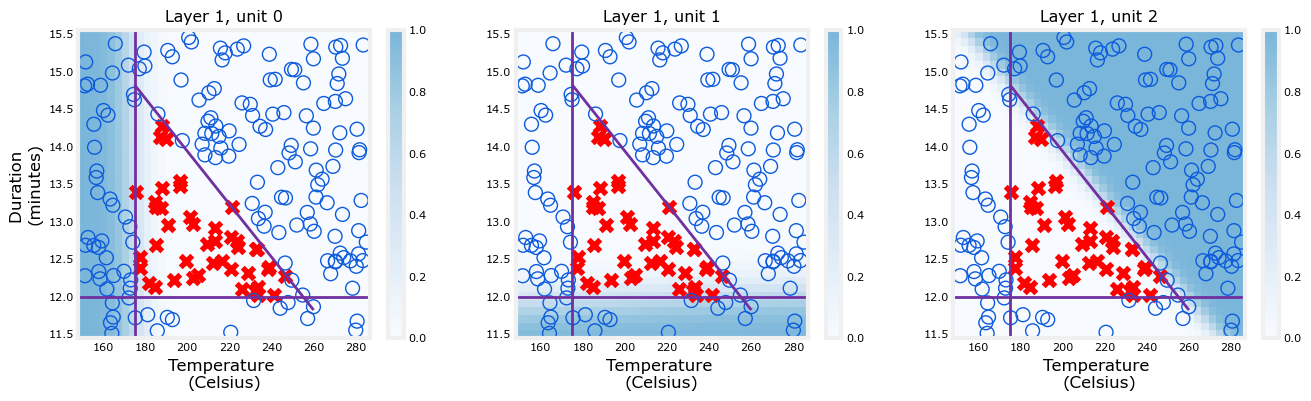

In [16]:
plt_layer(X,Y.reshape(-1,),W1,b1,norm_l)

음영은 각 유닛이 서로 다른 "불량 로스팅" 영역을 담당한다는 것을 보여줍니다. 유닛 0은 온도가 너무 낮을 때 더 큰 값을 갖습니다. 유닛 1은 지속 시간이 너무 짧을 때 더 큰 값을 가지며, 유닛 2는 시간/온도의 잘못된 조합에 대해 더 큰 값을 갖습니다. 네트워크가 경사 하강 과정을 통해 이러한 함수를 스스로 학습했다는 점은 주목할 가치가 있습니다. 이는 사람이 동일한 결정을 내리기 위해 선택할 수 있는 함수와 매우 유사합니다.

마지막 레이어의 함수 플롯은 시각화하기가 조금 더 어렵습니다. 입력은 첫 번째 레이어의 출력입니다. 우리는 첫 번째 레이어가 시그모이드를 사용하므로 출력 범위가 0과 1 사이라는 것을 알고 있습니다. 세 가지 입력의 가능한 모든 조합에 대한 출력을 계산하는 3D 플롯을 만들 수 있습니다. 이는 아래에 나와 있습니다. 위에서 높은 출력 값은 '불량 로스팅' 영역에 해당합니다. 아래에서 최대 출력은 3개의 입력이 '좋은 로스팅' 영역에 해당하는 작은 값인 영역입니다.

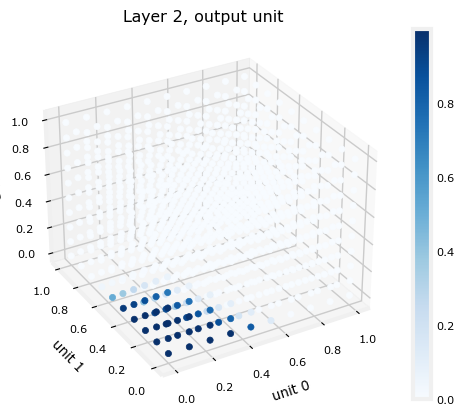

In [17]:
plt_output_unit(W2,b2)

최종 그래프는 작동 중인 전체 네트워크를 보여줍니다.
왼쪽 그래프는 파란색 음영으로 표시되는 최종 레이어의 원시 출력입니다. 이는 X와 O로 표시되는 훈련 데이터 위에 중첩됩니다.
오른쪽 그래프는 결정 임계값 이후 네트워크의 출력입니다. 여기서 X와 O는 네트워크가 내린 결정에 해당합니다.
다음을 실행하는 데 시간이 좀 걸립니다

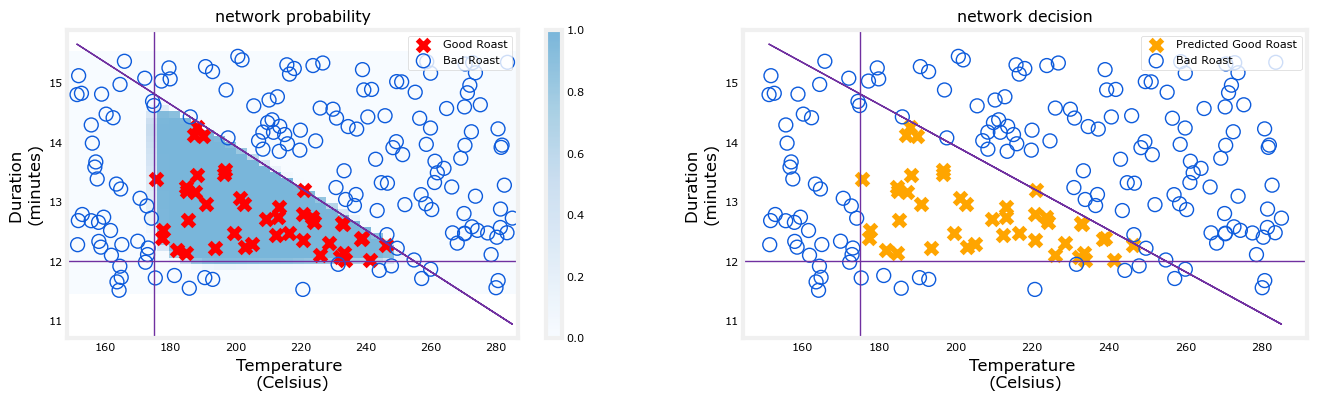

In [18]:
netf= lambda x : model.predict(norm_l(x), verbose=0)
plt_network(X,Y,netf)

## Congratulations!
Tensorflow에서 작은 신경망을 구축했습니다. 네트워크는 여러 유닛 간에 결정을 나누어 복잡한 결정을 처리하는 신경망의 능력을 보여주었습니다.